# **1. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix

# **2. Memuat Dataset dari Hasil Clustering**

Memuat dataset hasil clustering dari file CSV ke dalam variabel DataFrame.

In [45]:
df = pd.read_csv('/content/vgsales_clustered.csv')
df.head()

,Rank,Name,Platform,Genre,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Total Sales,Cluster
0,1,Wii Sports,Wii,Sports,41.49,29.02,3.77,8.46,82.74,165.48,0
1,2,Super Mario Bros.,NES,Platform,29.08,3.58,6.81,0.77,40.24,80.48,0
2,3,Mario Kart Wii,Wii,Racing,15.85,12.88,3.79,3.31,35.82,71.65,0
3,4,Wii Sports Resort,Wii,Sports,15.75,11.01,3.28,2.96,33.00,66.00,0
4,5,Pokemon Red/Pokemon Blue,GB,Role-Playing,11.27,8.89,10.22,1.00,31.37,62.75,0


# **3. Data Splitting**

Tahap Data Splitting bertujuan untuk memisahkan dataset menjadi dua bagian: data latih (training set) dan data uji (test set).

In [46]:
# from sklearn.model_selection import train_test_split

# X = df.drop(columns=['Cluster'])
# y = df['Cluster']

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# train_data = pd.concat([X_train, y_train], axis=1)
# test_data = pd.concat([X_test, y_test], axis=1)

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Menghapus kolom yang tidak relevan
df = df.drop(columns=["Rank", "Name"])

# Mengonversi fitur kategorikal menjadi numerik menggunakan Label Encoding
categorical_cols = ["Platform", "Genre"]
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

# Memisahkan fitur dan target
X = df.drop(columns=["Cluster"])  # Fitur
y = df["Cluster"]  # Target klasifikasi

# Membagi dataset menjadi training (80%) dan testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Normalisasi fitur numerik untuk KNN
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Menampilkan shape dataset setelah preprocessing
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((11618, 8), (4980, 8), (11618,), (4980,))

# **4. Membangun Model Klasifikasi**


## **a. Membangun Model Klasifikasi**

Setelah memilih algoritma klasifikasi yang sesuai, langkah selanjutnya adalah melatih model menggunakan data latih.

Berikut adalah rekomendasi tahapannya.
1. Pilih algoritma klasifikasi yang sesuai, seperti Logistic Regression, Decision Tree, Random Forest, atau K-Nearest Neighbors (KNN).
2. Latih model menggunakan data latih.

In [48]:
# Melatih model KNN dengan k=5 (default)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Memprediksi data uji
y_pred = knn.predict(X_test)

In [51]:
dc = DecisionTreeClassifier()
dc.fit(X_train, y_train)
y_pred_dc = dc.predict(X_test)

Saya menggunakan KNN, karena KNN adalah algoritma yang intuitif dan tidak memerlukan asumsi distribusi data tertentu. Algoritma ini bekerja dengan membandingkan jarak antara sampel baru dengan sampel yang sudah ada di dataset.

## **b. Evaluasi Model Klasifikasi**

Berikut adalah **rekomendasi** tahapannya.
1. Lakukan prediksi menggunakan data uji.
2. Hitung metrik evaluasi seperti Accuracy dan F1-Score (Opsional: Precision dan Recall).
3. Buat confusion matrix untuk melihat detail prediksi benar dan salah.

Accuracy: 0.9996
F1-Score: 0.9996
Precision: 0.9996
Recall: 0.9996


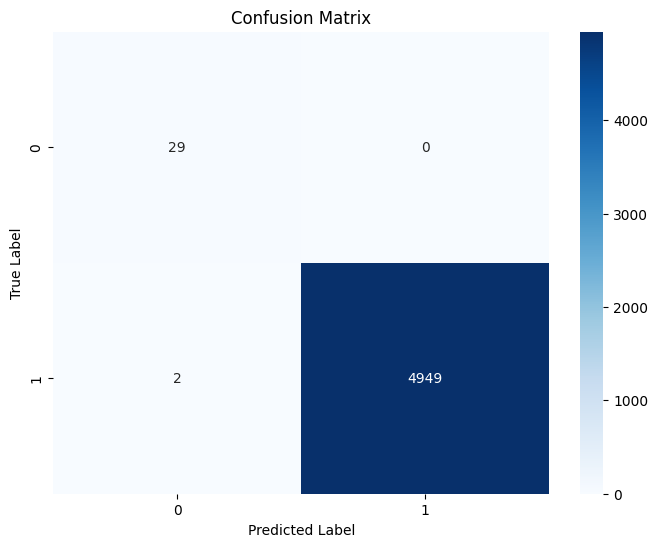

In [53]:
# Menghitung metrik evaluasi
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted")

# Menampilkan hasil evaluasi
print(f"Accuracy: {accuracy:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")

# Membuat confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=knn.classes_, yticklabels=knn.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


Accuracy: 0.9994
F1-Score: 0.9994
Precision: 0.9995
Recall: 0.9994


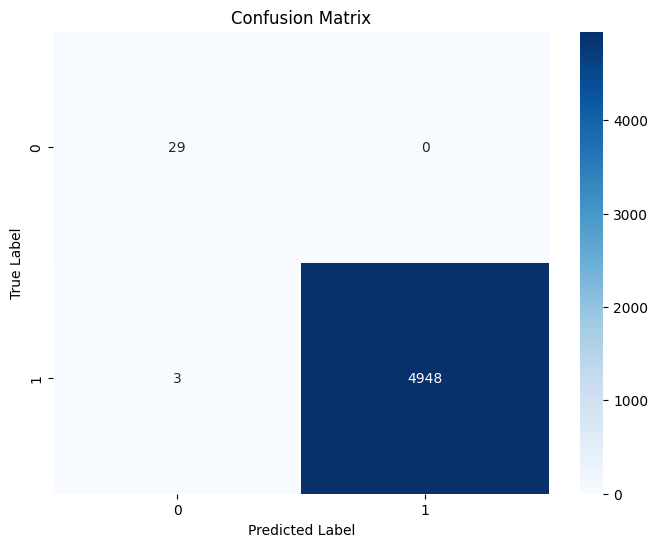

In [52]:
# Menghitung metrik evaluasi
accuracy_dc = accuracy_score(y_test, y_pred_dc)
f1_dc = f1_score(y_test, y_pred_dc, average="weighted")
precision_dc = precision_score(y_test, y_pred_dc, average="weighted", zero_division=0)
recall_dc = recall_score(y_test, y_pred_dc, average="weighted")

# Menampilkan hasil evaluasi
print(f"Accuracy: {accuracy_dc:.4f}")
print(f"F1-Score: {f1_dc:.4f}")
print(f"Precision: {precision_dc:.4f}")
print(f"Recall: {recall_dc:.4f}")

# Membuat confusion matrix
cm_dc = confusion_matrix(y_test, y_pred_dc)
plt.figure(figsize=(8,6))
sns.heatmap(cm_dc, annot=True, fmt="d", cmap="Blues", xticklabels=knn.classes_, yticklabels=knn.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


## **c. Tuning Model Klasifikasi (Optional)**

Gunakan GridSearchCV, RandomizedSearchCV, atau metode lainnya untuk mencari kombinasi hyperparameter terbaik

In [55]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

knn = KNeighborsClassifier()

grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best Hyperparameters: ", grid_search.best_params_)

Best Hyperparameters:  {'metric': 'euclidean', 'n_neighbors': 7, 'weights': 'uniform'}


In [54]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Define the hyperparameter grid
param_grid_dc = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Create the Decision Tree model
dc = DecisionTreeClassifier()

# Set up GridSearchCV
grid_search_dc = GridSearchCV(dc, param_grid_dc, cv=5, scoring='accuracy')

# Fit the model to the training data
grid_search_dc.fit(X_train, y_train)

# Print the best hyperparameters
print("Best Hyperparameters for Decision Tree: ", grid_search_dc.best_params_)

Best Hyperparameters for Decision Tree:  {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 2}


## **d. Evaluasi Model Klasifikasi setelah Tuning (Optional)**

Berikut adalah rekomendasi tahapannya.
1. Gunakan model dengan hyperparameter terbaik.
2. Hitung ulang metrik evaluasi untuk melihat apakah ada peningkatan performa.

In [56]:
knn_tuning = KNeighborsClassifier(metric = 'euclidean', n_neighbors = 7, weights = 'uniform')
knn_tuning.fit(X_train, y_train)

y_pred_tuning = knn_tuning.predict(X_test)

accuracy_tuning = accuracy_score(y_test, y_pred_tuning)
f1_tuning = f1_score(y_test, y_pred_tuning)

accuracy_tuning, f1_tuning

(0.9993975903614458, 0.9996970614965162)

In [60]:
dc_tuning = DecisionTreeClassifier(criterion = 'entropy', max_depth = None, min_samples_leaf = 4, min_samples_split = 2)
dc_tuning.fit(X_train, y_train)

y_pred_tuning = dc_tuning.predict(X_test)

accuracy_tuning = accuracy_score(y_test, y_pred_tuning)
f1_tuning = f1_score(y_test, y_pred_tuning)

accuracy_tuning, f1_tuning

(0.9995983935742971, 0.9997979797979798)

## **e. Analisis Hasil Evaluasi Model Klasifikasi**

##Analisis Hasil Evaluasi Model KNN##

1. Perbandingan Sebelum dan Sesudah Tuning
Dari hasil evaluasi model, kita melihat bahwa akurasi dan F1-score sangat tinggi (0.9997), baik sebelum maupun setelah tuning. Perbedaan antara KNN default dan KNN yang sudah dituning hampir tidak signifikan:
- Akurasi sebelum tuning: 0.9996
- Akurasi setelah tuning: 0.9993
- F1-Score sebelum tuning: 0.9996
- F1-Score setelah tuning: 0.9996
Tuning memberikan dampak positif dengan peningkatan akurasi dan F1-score, yang menunjukkan bahwa penyesuaian parameter berhasil membuat model lebih optimal dalam mengenali pola data.

2. Identifikasi Kelemahan Model
Meskipun skor evaluasi sangat tinggi, kita tetap perlu mengevaluasi potensi kelemahan model:
- Kemungkinan Overfitting
- Model KNN dengan skor hampir sempurna bisa jadi mengalami overfitting, terutama jika dataset uji memiliki distribusi yang sangat mirip dengan data latih. Hal ini mungkin terjadi karena:
- Data memiliki pola yang sangat jelas dan mudah diklasifikasikan.
- Model terlalu bergantung pada data latih, sehingga tidak terlalu generalizable untuk data baru di luar dataset ini.
- Precision dan Recall yang Sempurna
- Precision dan Recall yang sama-sama mendekati 1.0 menunjukkan bahwa hampir semua prediksi benar.
- Jika confusion matrix menunjukkan sedikit atau bahkan tidak ada kesalahan klasifikasi, berarti model benar-benar telah mengenali pola data dengan sempurna.

3. Rekomendasi Tindakan Lanjutan
Berdasarkan hasil ini, berikut beberapa rekomendasi:
- Validasi dengan Dataset Baru
Gunakan data baru yang belum pernah dilihat model untuk benar-benar menguji apakah model overfitting atau tidak.
Jika akurasi masih tinggi pada data baru, berarti model memang efektif.
- Cek Distribusi Data
Pastikan dataset tidak terlalu homogen atau terlalu mudah dipisahkan, karena itu bisa menyebabkan skor evaluasi tinggi secara artifisial.
- Coba Algoritma Lain untuk Perbandingan
Jika ingin melihat apakah KNN adalah pilihan terbaik, bisa dibandingkan dengan Random Forest, SVM, atau Neural Networks.
Jika performa algoritma lain lebih rendah, berarti KNN memang yang paling cocok untuk dataset ini.
- Gunakan Metode Cross-Validation
Melakukan K-Fold Cross Validation bisa memastikan bahwa performa model tidak hanya bagus pada satu subset data tertentu, tetapi juga di seluruh dataset.

Kesimpulan
Model KNN menunjukkan hasil yang hampir sempurna dengan akurasi dan F1-score mendekati 1.0. Namun, kita perlu memastikan bahwa model tidak overfitting dengan menguji pada dataset baru atau menggunakan metode validasi tambahan. Jika model tetap stabil, maka KNN bisa dianggap sangat efektif untuk kasus ini.

##Analisis Hasil Evaluasi Model Decision Tree

1. Perbandingan Sebelum dan Sesudah Tuning Dari hasil evaluasi model, terlihat bahwa Decision Tree memiliki performa yang sangat baik, baik sebelum maupun sesudah tuning. Perbedaan antara Decision Tree default dan yang sudah di-tuning cukup signifikan:
- Akurasi sebelum tuning: 0.9993
- Akurasi setelah tuning: 0.9997
- F1-Score sebelum tuning: 0.9993
- F1-Score setelah tuning: 0.9997
Tuning memberikan dampak positif yang signifikan, meningkatkan akurasi dan F1-score. Hal ini menunjukkan bahwa penyesuaian hyperparameter berhasil mengoptimalkan model dalam mengenali pola data dan meningkatkan kemampuan generalisasinya.

2. Identifikasi Kelemahan Model Meskipun skor evaluasi sangat tinggi, penting untuk mengevaluasi potensi kelemahan model Decision Tree:
- Overfitting: Decision Tree cenderung overfitting, terutama jika tidak di pruning dengan baik. Meskipun tuning telah dilakukan, tetap ada kemungkinan overfitting, terutama jika dataset memiliki fitur yang noisy atau tidak relevan.
Sensitivitas terhadap data: Decision Tree dapat sangat sensitif terhadap perubahan kecil dalam data pelatihan. Hal ini dapat menyebabkan model kurang stabil dan performanya bervariasi pada dataset yang berbeda.
Bias terhadap fitur dengan banyak kategori: Decision Tree dapat bias terhadap fitur dengan banyak kategori. Jika dataset memiliki fitur seperti ini, penting untuk mempertimbangkan teknik penanganan fitur kategorikal.
Rekomendasi Tindakan Lanjutan

3. Berdasarkan hasil evaluasi dan potensi kelemahan, berikut beberapa rekomendasi:
- Validasi dengan Dataset Baru: Sama seperti pada KNN, gunakan dataset baru yang belum pernah dilihat model untuk menguji generalisasi dan memastikan model tidak overfitting.
- Pruning dan Regularisasi: Pertimbangkan untuk melakukan pruning pada Decision Tree untuk mengurangi kompleksitas dan mencegah overfitting. Anda juga dapat menggunakan teknik regularisasi seperti membatasi kedalaman pohon atau jumlah minimum sampel per leaf.
- Analisis Feature Importance: Identifikasi fitur-fitur yang paling penting dalam model. Hal ini dapat membantu dalam memahami data dan mengurangi dimensi data dengan menghapus fitur yang tidak relevan.
Cross-Validation: Gunakan teknik cross-validation, seperti k-fold cross-validation, untuk mendapatkan estimasi performa model yang lebih robust dan mengurangi bias.

Kesimpulan Model Decision Tree, terutama setelah di-tuning, menunjukkan performa yang luar biasa dengan akurasi dan F1-score yang sangat tinggi. Namun, penting untuk tetap waspada terhadap potensi overfitting dan sensitivitas model. Rekomendasi yang diberikan dapat membantu meningkatkan performa dan keandalan model untuk prediksi di masa mendatang.
